# A0 Dense Flash LegalGPT — Complete Illustrated Source Audit

**CS781 Capstone · Phase 1 · Architecture A0 ONLY**

This document explains the actual supplied A0 implementation in reproducible detail, from **official legal documents, imported-but-trained BPE, corpus splitting, embeddings, RMSNorm, MHA/12 heads/RoPE, SwiGLU, training windows and AdamW, to validation/checkpointing, greedy cached inference, and test submission**. All image diagrams in this notebook are **embedded attachments**, so they are viewable without downloading a separate figures folder.

**Source:** `code/architecture_a_legalgpt.py` in the accompanying ZIP. See repository `README.md`, `docs/A0_TECHNICAL_REFERENCE.md`, `docs/CODE_MAP.md`, and `report/A0_Methodology_Report.pdf` for full, line-level coverage.

**Evidence:** The code was read and its tiny built-in self-test passed. This notebook contains *analytical* figures and illustrative examples, not measured training/validation curves. No 110M-parameter training, dataset download, Codabench score, or checkpoint is claimed by this document.\n\n**Important:** 512 and 128 in the competition refer to **whitespace words**, while 2048 in training is a **BPE-token context length**, and 2048 in SwiGLU is a **neuron count**. These are different quantities.

### End-to-end corpus → tokenizer → Transformer → validation → inference

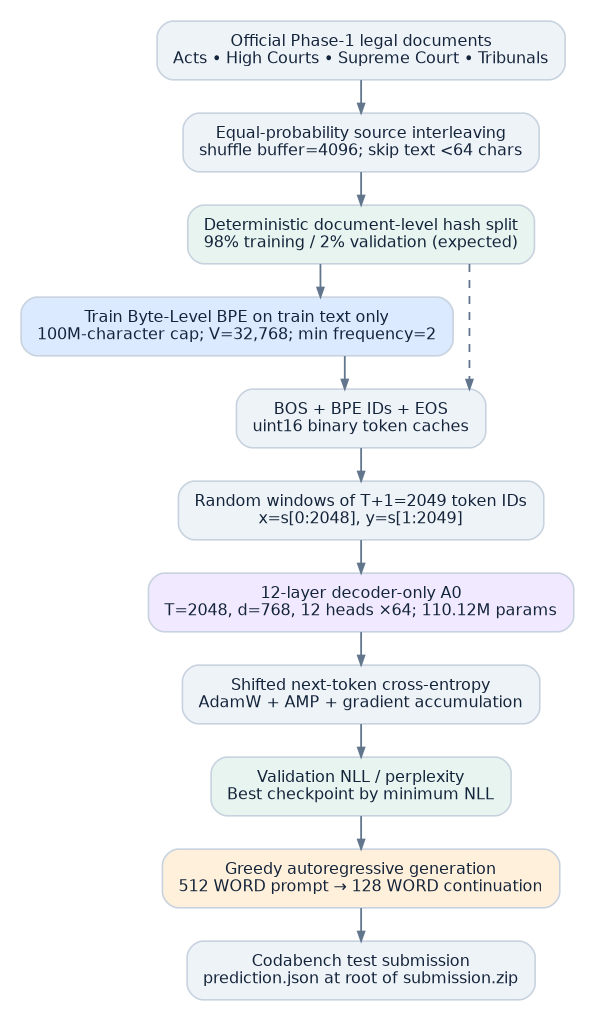

## 1. Direct source reproduction

The core model is in one 1,377-line Python script, plus an original Colab launcher and RTX shell launchers. It was **not** written from scratch as a tokenizer algorithm, but was **trained from scratch** as a separate BPE vocabulary, and the Transformer starts from random weights.

Run from `code/`:

```bash
python -m pip install -r requirements.txt
python architecture_a_legalgpt.py --mode selftest
python architecture_a_legalgpt.py --mode prepare --workdir ./runs/A0_dense_flash --vocab_size 32768 --tokenizer_train_chars 100000000 --prepare_train_tokens 200000000 --prepare_val_tokens 5000000 --val_generation_examples 128 --mix_mode equal --seed 781
python architecture_a_legalgpt.py --mode train --workdir ./runs/A0_dense_flash --max_seq_len 2048 --micro_batch_size 1 --grad_accum_steps 32 --learning_rate 3e-4 --weight_decay 0.1 --target_train_tokens 200000000 --eval_every 100 --eval_batches 32 --save_every 100 --log_every 10
python architecture_a_legalgpt.py --mode eval --workdir ./runs/A0_dense_flash --strategy greedy --eval_generation_limit 32
python architecture_a_legalgpt.py --mode submit --workdir ./runs/A0_dense_flash --strategy greedy
```

The cells below avoid large training. They calculate exact shapes and test only small synthetic tensors. The local code scripts, not this explanatory notebook, are the full-scale training/inference implementation.

## 2. BPE vocabulary learning — EXACT selection behavior

- Load only official Phase 1 legal training documents from the four streamed source files; filter texts shorter than 64 characters and exclude documents selected into the deterministic SHA1 2% validation partition.
- Fit a **new** Hugging Face `tokenizers.Tokenizer(tokenizers.models.BPE(unk_token="<unk>"))`; `ByteLevel(add_prefix_space=False)` pre-tokenization; `ByteLevelDecoder()` decoding. No hand-written BPE trainer or pretrained tokenizer is used.
- `BpeTrainer(vocab_size=32768,min_frequency=2,special_tokens=["<pad>","<bos>","<eos>","<unk>"],show_progress=True)` consumes up to 100,000,000 *raw Python characters* of non-validation documents.
- Inside imported BPE, pair-count frequencies select the **highest-frequency eligible adjacent pair** for the next merge. Merge rules are learned sequentially; the next pair frequencies change after each merge. There is **no independent fixed M**, no top-k/top-p and no beam search in tokenizer training.
- `tokenizer/tokenizer.json` contains the actual merge list and IDs; `tokenizer_meta.json` contains actual learned vocabulary size and text/doc counts. Those generated files are not included in the source-only archive, so this notebook does not fabricate the actual learned merges.
- After fitting, *freeze the tokenizer rules*, encode each document using `[bos] + tokenizer.encode(text).ids + [eos]`, and append IDs to packed uint16 caches. No per-document padding.

The example below is an **illustrative character-level toy**, deliberately distinct from the actual Hugging Face byte-level tokenizer implementation.

In [1]:
from collections import Counter

texts = ['hug']*10 + ['pug']*5 + ['pun']*12 + ['bun']*4 + ['hugs']*5
pieces = [list(w) for w in texts]
def count_adjacent_pairs(sequences):
    return Counter((a,b) for seq in sequences for a,b in zip(seq,seq[1:]))

freq = count_adjacent_pairs(pieces)
print('Toy pair counts (first 6):', freq.most_common(6))
selected, count = freq.most_common(1)[0]
print('Most frequent toy pair:', selected, 'frequency:', count)
# This demonstrates frequency-based greediness; it is NOT an A0 tokenizer.json merge list.

Toy pair counts (first 6): [(('u', 'g'), 20), (('p', 'u'), 17), (('u', 'n'), 16), (('h', 'u'), 15), (('g', 's'), 5), (('b', 'u'), 4)]
Most frequent toy pair: ('u', 'g') frequency: 20


### Packed documents, BOS/EOS and shifted next-token windows

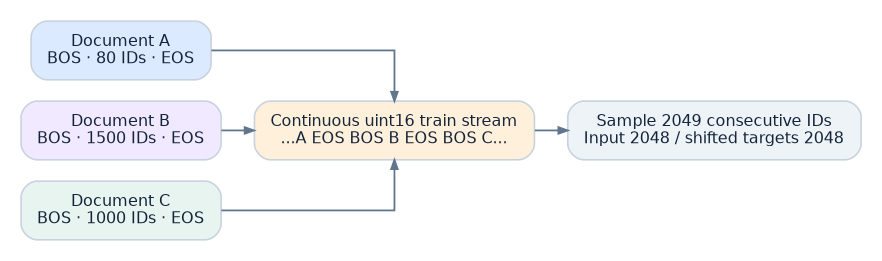

## 3. Training example: why there is no fixed 512→128 training tensor

A0's training cache contains the concatenated BPE IDs of legal documents. `RandomMemmapBatcher` uses `np.memmap(..., dtype=np.uint16)` and samples **2049 contiguous IDs** per example. Define `s[0],...,s[2048]`, and construct `x=s[0:2048]` and `y=s[1:2049]`. The model calculates 2048 parallel, **causally masked** next-token predictions, each with vocabulary-size scores. EOS/BOS positions still contribute to loss; model attention can cross a document boundary. Micro-batch B=1, T=2048, gradient accumulation=32 → 65536 processed token positions per optimizer update on one GPU.

**Avoid confusion:** A 512-WORD prompt is created only in the **generation-validation and testing** pathways. A document with fewer than 640 whitespace-separated words is not used as a local 512+128-word validation window; this does not exclude such documents from the packed training token cache.

In [2]:
import numpy as np
T = 2048
s = np.arange(T+1, dtype=np.int64)     # illustrative token IDs; not actual legal text
x = s[:-1]
y = s[1:]
assert len(x) == len(y) == 2048
assert np.array_equal(x[1:],y[:-1])
print('Training x shape:', x.shape, 'targets y shape:', y.shape)
print('First 5 input IDs:', x[:5], 'First 5 target IDs:', y[:5])

Training x shape: (2048,) targets y shape: (2048,)
First 5 input IDs: [0 1 2 3 4] First 5 target IDs: [1 2 3 4 5]


## 4. Embeddings and the 12-layer model: exact dimensions

Tokenizer vocabulary V=32768 (requested, but the actual training code adjusts to the fitted tokenizer's realized vocab), embedding matrix \(E\in\mathbb{R}^{32768\times768}\). Input token IDs [2048] select 2048 rows of E and give hidden states [2048,768]. Each of 12 decoder blocks consumes/produces [2048,768]. A separate learned output embedding matrix is **not** used: `lm_head.weight = tok_embeddings.weight`, so final logits are \(Z=H_fE^\top\) of shape [2048,32768]. E receives gradient from both input token lookup and output vocabulary classification.

No learned absolute positional embedding is added at input; RoPE rotates Q/K inside the 12 attention blocks. Linear layers are bias-free. The model has 110,119,680 **unique** scalars in the nominal 32,768-vocabulary configuration.

### One Pre-Norm block: exact order and residual bypasses

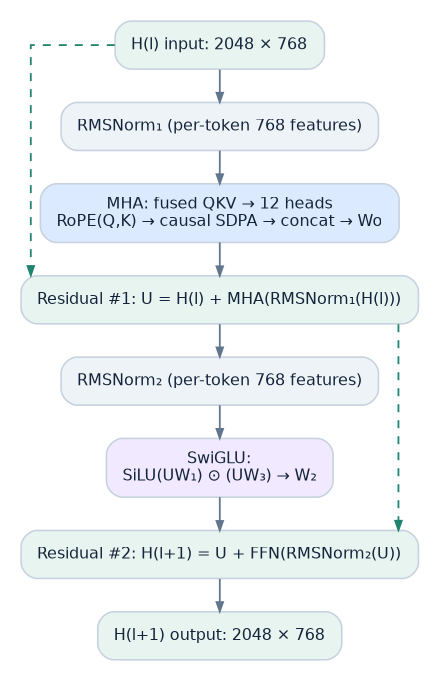

## 5. RMSNorm within each block

For one input token vector \(x\in\mathbb{R}^{768}\), A0 calculates \(\gamma_j x_j/\sqrt{\tfrac1{768}\sum_{k=1}^{768}x_k^2+10^{-6}}\). It does **not subtract the mean** and **does not normalize across the 2048 positions**. The implementation uses float32 for the reduction then casts back before gain multiplication. Each block has RMSNorm **before MHA**, and a separate RMSNorm **before SwiGLU**, followed by two *outside-the-normalization* residual additions. There is also a 25th **final** RMSNorm after 12 blocks (12×2+1).

## 6. Multi-head attention: each of 12 heads sees all T=2048 tokens

Fused bias-free projection `Linear(768,2304)` gives Q,K,V of shape [2048,768]. Reshape **features** into 12 independent subspaces of 64: Q,K,V are `[12,2048,64]` (batch omitted), **NOT 12 sets of roughly 171 tokens**. Head i has `Q_i @ K_i.T` shape [2048,2048], scaled by `sqrt(64)=8`, causally masked and softmax normalized, then multiplied by the unrotated values V_i to [2048,64]. Concatenate 12 heads back to [2048,768], pass through W_O [768,768]. All heads have their own learned projection slices. Tensor operations are dispatched through PyTorch `F.scaled_dot_product_attention`; Flash may be chosen when compatible with device/backend.

### Q/K/V projection, RoPE and per-head tensor sizes

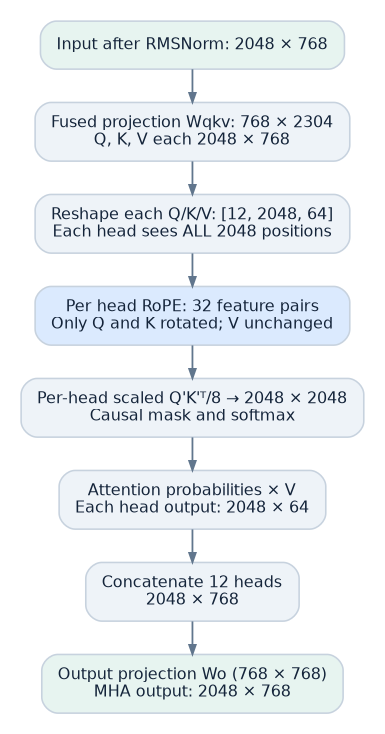

## 7. RoPE — explicit pairwise rotation and relative-distance identity

RoPE does not independently multiply each of 64 real numbers by a complex exponential. For each head, 64 features are **32 neighboring (even,odd) pairs**. Token row `m` (0…2047), pair `i` (0…31) uses \(\theta_i = 10000^{-2i/64}\) and angle \(\phi_{m,i}=m\theta_i\). For Q values `(a,b)`, the rotated coordinates are `(a*cos(phi)-b*sin(phi), a*sin(phi)+b*cos(phi))`; K is rotated identically and V is not rotated. These 32 simultaneous 2×2 rotations form a 64×64 block-diagonal matrix \(R_m\). \((R_mq)^T(R_nk)=q^TR_{n-m}k\) makes attention dot products position-sensitive through relative offset. The code precomputes [2048,32] sin/cos buffers, not trainable frequencies, and uses cache-length offsets for generation.

In [3]:
import numpy as np
m,i,dh = 1,0,64
rotation_frequency = 10000.0**(-2*i/dh)
phi = m * rotation_frequency
original = np.array([2.0,1.0])
R = np.array([[np.cos(phi), -np.sin(phi)],[np.sin(phi), np.cos(phi)]])
rotated = R @ original
assert np.allclose(np.linalg.norm(original),np.linalg.norm(rotated))
print('phi:',phi,'original pair:',original,'rotated:',np.round(rotated,6))
# Exact code corresponding to A0 RotaryEmbedding.apply_rotary:
# xe=x[...,0::2]; xo=x[...,1::2]
# ye=xe*cos-xo*sin; yo=xe*sin+xo*cos
# result=torch.stack((ye,yo),dim=-1).flatten(-2)

phi: 1.0 original pair: [2. 1.] rotated: [0.239134 2.223244]


## 8. Attention does NOT equal RoPE

After RoPE, A0 applies standard causal scaled dot-product attention to **rotated** Q/K and unchanged V. The future-mask is distinct from RoPE: for query row m, all keys n>m are blocked; the attention matrix is conceptually 2048×2048. At training or prompt prefill `is_causal=True`. During one-token cached inference `is_causal=False` because all cached K/V are previous or current positions. Flash SDPA optimizes IO without changing the exact dense-attention mathematical objective or the O(T²) arithmetic order.

## 9. SwiGLU: two fully connected branches and exact gating operation

Let a single **normalized** token representation be x in R^768. Branch A: a=xW1 (W1:[768,2048]); Branch B: b=xW3 (W3:[768,2048]); both bias-free and fully connected. Compute SiLU(a)=a*sigmoid(a) elementwise, multiply *elementwise* by unbounded b, then project via W2:[2048,768]. Formula: \(f(x)=[\mathrm{SiLU}(xW_1)\odot(xW_3)]W_2\). This is **not** `[sigmoid(xW1)*xW3]` and is **not** two branches concatenated. All 2048 token rows use the same three learned weight matrices, independently, so attention mixes positions and FFN mixes **features**. The FFN hidden width 2048 is separate from sequence length 2048.

### Fully connected SwiGLU with sigmoid INSIDE SiLU

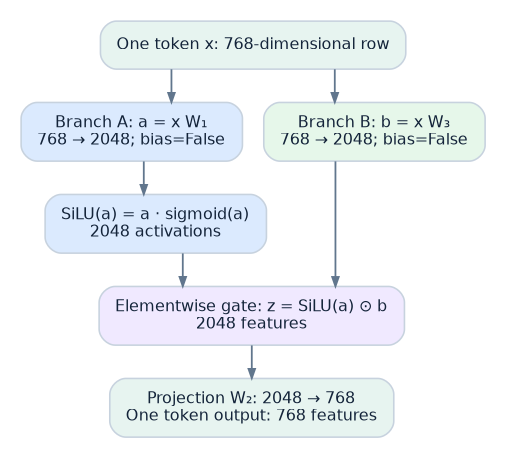

In [4]:
import numpy as np
# Toy feature values to see the multiplicative gate (these are not model weights).
a=np.array([2.0,-1.0,0.5]); b=np.array([0.5,2.0,0.0])
sigmoid=lambda z: 1/(1+np.exp(-z))
silu=a*sigmoid(a)
product=silu*b
for j in range(len(a)):
    print(f'hidden j={j}: a={a[j]:.3f}, sigmoid(a)={sigmoid(a[j]):.3f}, '
          f'SiLU={silu[j]:.3f}, b={b[j]:.3f}, gated={product[j]:.3f}')

hidden j=0: a=2.000, sigmoid(a)=0.881, SiLU=1.762, b=0.500, gated=0.881
hidden j=1: a=-1.000, sigmoid(a)=0.269, SiLU=-0.269, b=2.000, gated=-0.538
hidden j=2: a=0.500, sigmoid(a)=0.622, SiLU=0.311, b=0.000, gated=0.000


## 10. The two residual equations, repeated 12 times

\(U = H + \mathrm{MHA}(\mathrm{RMSNorm}_1(H))\); \(H_{out} = U + \mathrm{SwiGLU}(\mathrm{RMSNorm}_2(U))\). The identity branch bypasses the normalization and sublayer weights, a key difference from Post-Norm. With initial shape [2048,768], output after every layer is [2048,768]. After all 12 layers, apply a final RMSNorm and tied output projection to [2048,32768] logits; training `F.cross_entropy` takes these logits without an explicit model softmax.

## 11. Exact parameter-count accounting

A0 params: tied token embedding V*d=25,165,824; each block fused QKV 3d²=1,769,472, attention output d²=589,824, three FFN matrices 3*d*dff=4,718,592, two normalization gains 2d=1,536 → 7,079,424 per block; 12 blocks → 84,953,088; final normalization gain d=768. Total **110,119,680 unique parameters**. RoPE has no learned parameters. All linear layers have no bias.

### Exact parameter allocation (analytical, not training result)

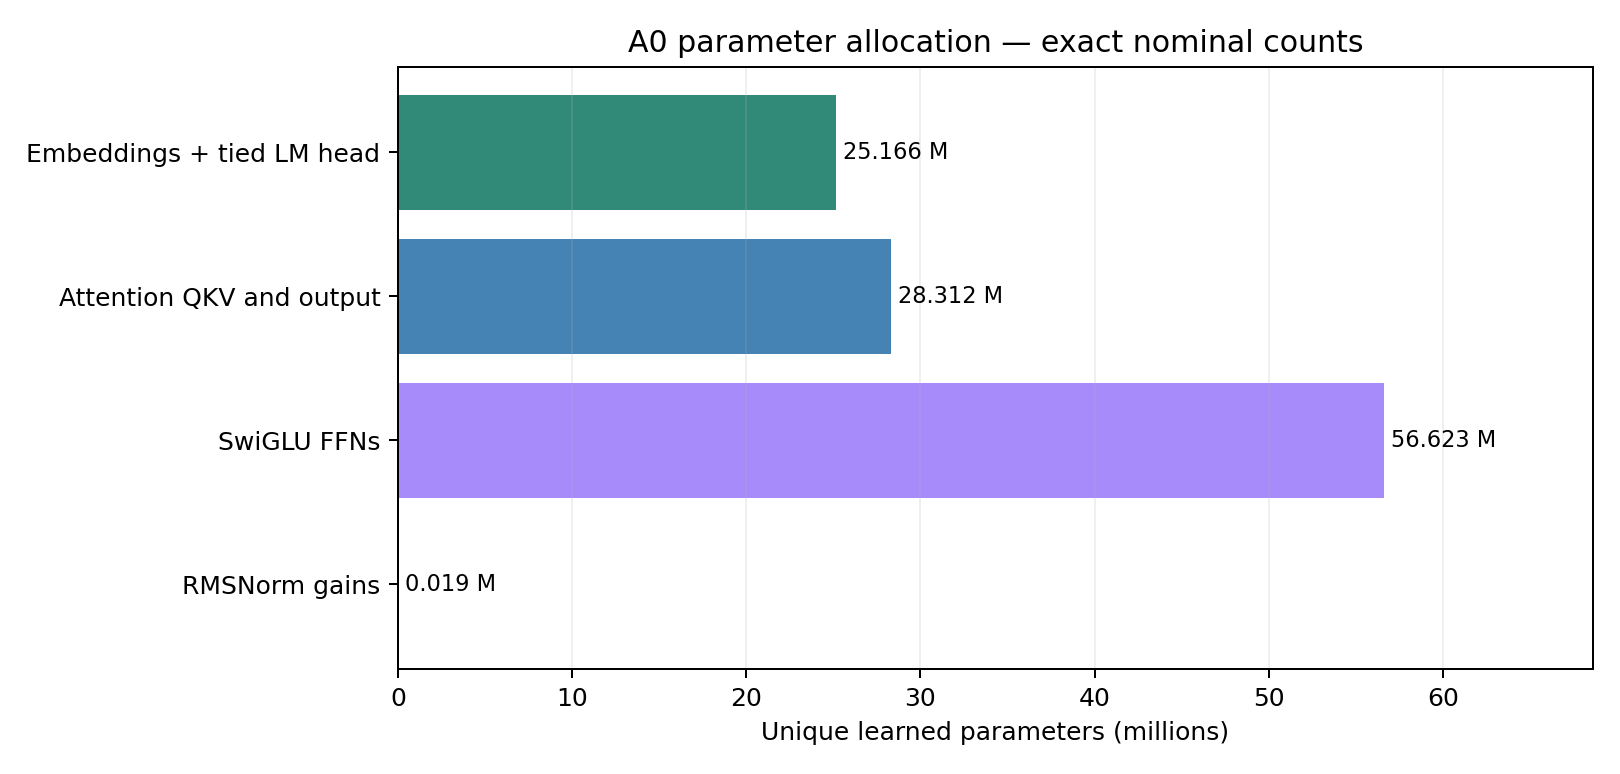

In [5]:
V,d,L,H,dh,dff=32768,768,12,12,64,2048
embedding=V*d
per_block=3*d*d+d*d+3*d*dff+2*d
n_params=embedding+L*per_block+d
print('embedding/tied head=',f'{embedding:,}')
print('per block=',f'{per_block:,}')
print('nominal total=',f'{n_params:,}')
assert H*dh == d and n_params == 110_119_680

embedding/tied head= 25,165,824
per block= 7,079,424
nominal total= 110,119,680


## 12. Initialization, optimization, numerical behavior and step counts

Linear and embedding weights initially Normal(0,0.02²). Residual-output projections Wo and W2 reinitialize with std `0.02/sqrt(2*12)`. RMSNorm gains start as ones. `AdamW` peak LR 3e-4, `betas=(0.9,0.95)`, eps 1e-8, decay 0.1 for parameter matrices (ndim≥2), 0 for gains. Warmup is first ~2% optimizer steps; cosine decay to 10% peak. Global clip grad norm 1.0. On CUDA fused AdamW attempted then fallback. BF16 autocast when supported, else FP16+GradScaler; CPU float32. Activation checkpointing enabled for 12 blocks during train, saving activation memory at recomputation cost. Optional DDP uses NCCL and rank-dependent seeds. On one GPU `tokens_per_step = 1*2048*32 = 65536`, so the 200M budget maps to **3052 planned optimizer steps**; actual completed steps require logs.

### Training, validation loss and checkpoint selection

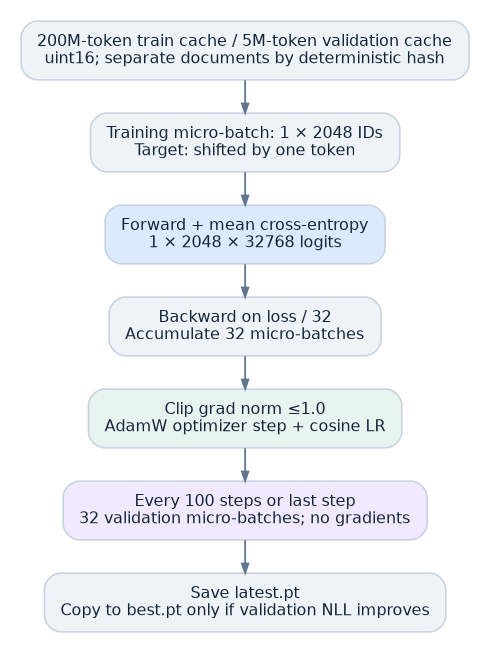

## 13. Validation and model selection (NOT Codabench testing)

Every 100 optimizer steps, and at final planned step, validation samples `eval_batches=32` micro-batches from a **separate** validation `uint16` cache; no backward; uses `model.eval()` and `torch.no_grad()`. Mean loss is negative log-likelihood; perplexity is `exp(loss)`. Checkpoint selection is **strictly lowest validation NLL**, not BERTScore. It atomically writes `latest.pt` and copies to `best.pt` when improved. Training resumes from `latest.pt`; inference loads `best.pt` if it exists. Optimizer and AMP scaler states are saved, but complete RNG state is not. A separate `--mode eval` calls generator on 32 held-out 512/128-word windows by default, computes ROUGE-L and SacreBLEU, and optionally local BERTScore only when explicitly allowed. No actual curve or score exists in the supplied source ZIP.

## 14. Inference: greedy decoding, KV cache and stopping rule

A 512-word prompt becomes a variable-length BPE sequence of N tokens after prepending BOS. Reject if N≥(2048−16)=2032. Prefill produces `[1,N,32768]` logits, uses only the *last* row, and retains 12 layers of K/V caches. For next-token logits, PAD/BOS/EOS/UNK are masked to −∞, previously generated token IDs are penalized by 1.05, and `argmax` selects next token (default `strategy=greedy`). **Greedy ignores the configured temperature 0.8, top-k=50 and top-p=0.90.** Optional `topk`/`nucleus` perform temperature-normalized multinomial sampling. **No beam search exists.** New token is appended, decoder is called on that *single* token using KV cache, and decoded output is checked with `re.findall(r"\S+",text)`. It stops at **128 words**, with hard cap `min(384,2048-N)` BPE tokens; it raises if there are still fewer than 128 words. This is fundamentally different from the 2048-position *parallel next-token loss* during training.

### Autoregressive inference and KV reuse

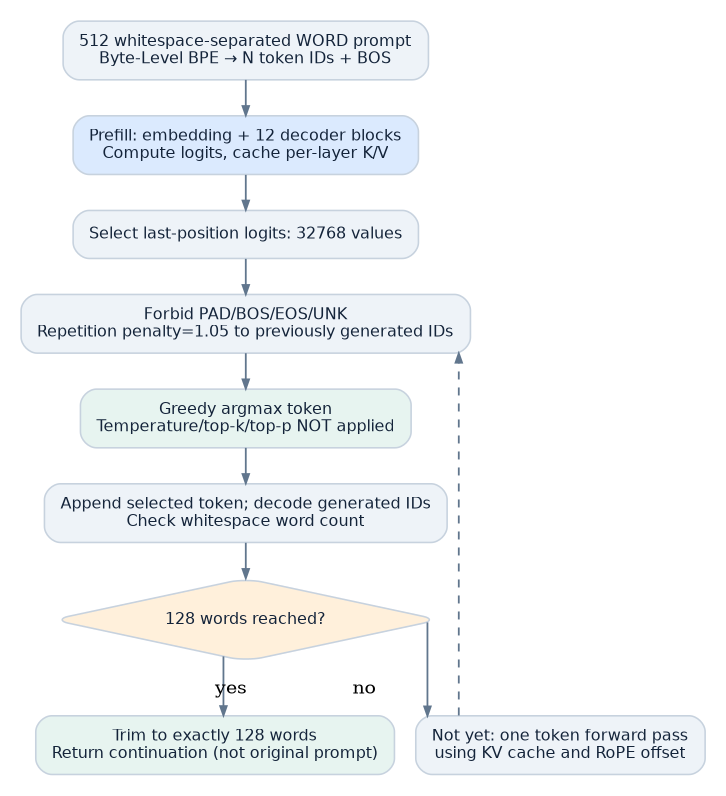

## 15. Tensor and memory ledger: all major dimensions

| Stage | One training example (batch omitted) | Notes |
|---|---|---|
| Input IDs / shifted targets | 2048 / 2048 | read 2049 adjacent IDs |
| Embedding | 2048×768 | lookup shared E |
| RMSNorm 1 | 2048×768 | per row over 768 |
| Fused QKV | 2048×2304 | learned 768×2304 |
| Each Q/K/V head | 2048×64 | 12 heads, all 2048 tokens |
| Sin/cos RoPE table | 2048×32 each | positions × coordinate pairs |
| Per-head attention scores | 2048×2048 | conceptual dense matrix |
| Head output | 2048×64 | attention weights × V |
| MHA concat/output | 2048×768 | Wo 768×768 |
| FFN branch A/B | 2048×2048 each | 768→2048 two branches |
| Gated FFN hidden | 2048×2048 | elementwise product |
| FFN output | 2048×768 | W2 2048→768 |
| Block output | 2048×768 | 12 successive blocks |
| Final logits | 2048×32768 | E.T 768×32768 |
| Cross-entropy | Scalar | over 2048 labels |

All memory chart values below are **analytic estimates, not profiler traces**.

### Parameter, optimizer, logits and KV-cache memory estimates

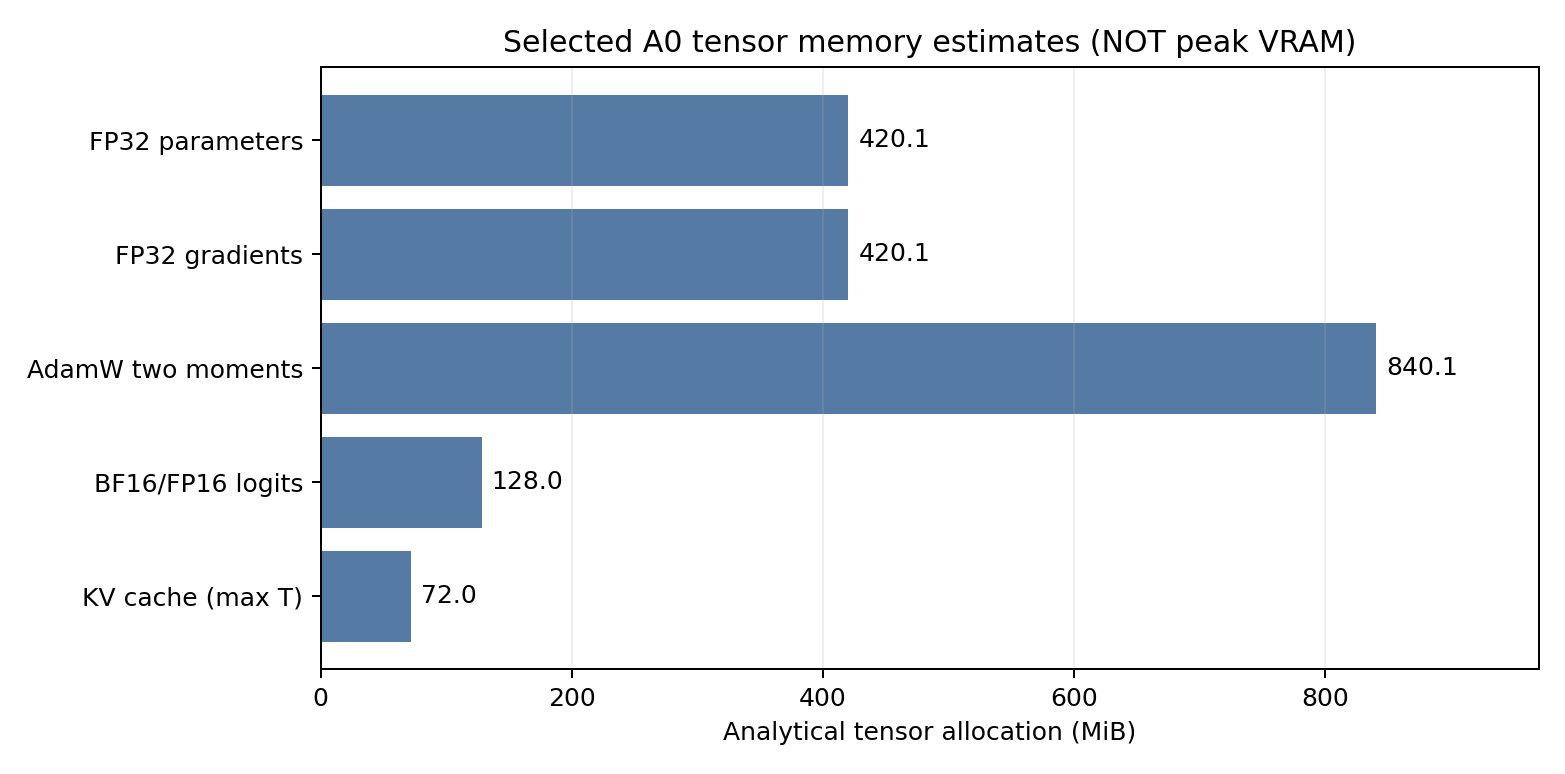

In [6]:
P=110119680
print('FP32 weights MiB:', round(4*P/2**20,2))
print('FP32 gradients MiB:', round(4*P/2**20,2))
print('2 AdamW moment tensors MiB:', round(8*P/2**20,2))
print('FP16 logits MiB:', round(2*2048*32768/2**20,2))
print('Theoretical full 12-layer FP16 KV cache MiB:', round(2*12*2*12*2048*64/2**20,2))
print('These quantities are NOT summed to estimate peak GPU memory.')

FP32 weights MiB: 420.07
FP32 gradients MiB: 420.07
2 AdamW moment tensors MiB: 840.15
FP16 logits MiB: 128.0
Theoretical full 12-layer FP16 KV cache MiB: 72.0
These quantities are NOT summed to estimate peak GPU memory.


## 16. Evidence boundaries and reproduction caveats

**Actual source-only audit proves:** API choices, tensor shapes, default configuration, checkpoint and decoder rules, and source identity. **Tiny model smoke test** proves only a small model's forward CE and one-token KV-cache extension. It **does not** establish actual 200M-token training completion, fitted BPE vocabulary size/merge list, trained checkpoint, loss curves, peak VRAM, Flash dispatch choice or Codabench score. `run_config.json` is overwritten on each CLI call; archive the actual training command/checkpoint state. Original requirements specify minimum rather than pinned dependency versions, and source URL resolves mutable `main`; strict bitwise reproduction requires pinning versions, dataset SHA and runtime environment. Randomness state is not fully restored on resume, and packed document boundaries are not masked.

**Source references:** `docs/CODE_MAP.md`, `docs/SOURCE_MANIFEST.md`, `docs/VALIDATION_CHECKLIST.md`; IITK CS781 Module 2.2 and 2.3 lecture PDFs; RoFormer position formulation; source PyTorch/HF libraries. This notebook contains no fabricated measured results.

## 17. Optional tiny model self-test using THE ORIGINAL A0 SOURCE

This cell imports the **unchanged** accompanying `architecture_a_legalgpt.py` and calls its built-in `self_test()`. The test intentionally creates a tiny 2-layer model rather than allocating 110M parameters and does not require downloading the legal dataset.

If executed from a standalone copy without the source package, place `architecture_a_legalgpt.py` in the notebook directory or one of the paths listed. Requires installed PyTorch, NumPy and `torch.utils.checkpoint`.

In [7]:
from pathlib import Path
import importlib.util, sys
candidates=[Path('../code/architecture_a_legalgpt.py'),
            Path('code/architecture_a_legalgpt.py'),
            Path('architecture_a_legalgpt.py')]
found=next((p for p in candidates if p.exists()),None)
if found is None:
    print('Original source not found alongside notebook. Download the accompanying package first.')
else:
    spec=importlib.util.spec_from_file_location('a0_original',str(found.resolve()))
    mod=importlib.util.module_from_spec(spec)
    sys.modules[spec.name]=mod
    spec.loader.exec_module(mod)
    mod.self_test()
    print('Original A0 Python source imported from:',found.resolve())

[selftest] testing model forward/cache/generation primitives
[selftest] PASS; tiny params=98,624
Original A0 Python source imported from: /mnt/data/A0_documentation_work/A0_Reproducibility_Package/code/architecture_a_legalgpt.py


## 18. Source-to-report mapping, public repo and final submission

| Requirement | Location in accompanying bundle |
|---|---|
| Exact A0 Python source | `code/architecture_a_legalgpt.py` |
| Original Colab entry point | `code/Architecture_A_LegalGPT_Colab.ipynb` |
| Original RTX execution scripts | `code/rtx/` |
| Every function and its source lines | `docs/CODE_MAP.md` |
| Source hashes/provenance | `docs/SOURCE_MANIFEST.md` |
| Comprehensive explanation and reasons | `README.md`, `docs/A0_TECHNICAL_REFERENCE.md` |
| Insertion-ready methodology | `report/A0_Methodology_Report.md` / PDF |
| Source-accurate graphics | `figures/` and this notebook's attachments |
| Evidence/validation audit | `docs/VALIDATION_CHECKLIST.md` |

The separate **Codabench** ZIP contains only `prediction.json`; the course's final **Hello IITK** ZIP must contain `code/` and `report/` directly at root. A public GitHub repository URL must be supplied separately; a local artifact or ZIP alone is not proof of a GitHub commit. This notebook is scoped to **A0**, and it does not prove A0 is the best of all Phase 1 variants.

### AI usage declaration for this documentation

AI assistance was used to audit and explain the supplied A0 code, derive theoretical tensor and memory counts, and draft technical diagrams/documentation. The author must independently verify all final source, experiment outputs, evaluation metrics and required institutional declarations. No full-model training was performed by this explanatory notebook.